# 05 · Did it work?

This notebook replays every morning from 1 Sep to 20 Dec 2024, a period the model never saw while
it was being built. On the first of each month every method learns from what was known by then.
Every morning at 8am it orders each business's waiting quotes. Only afterwards do I look up which
quotes actually said yes. A morning counts when the owner has a real choice: at least two quotes
waiting for one call.

The ranges in brackets come from re-running each comparison 1,000 times on random re-draws of
the businesses (a bootstrap) and keeping the middle 95%. Whole businesses are re-drawn because
one business's mornings are alike, and every method is scored on the same re-draws, so the
comparisons are like-for-like (Field and Welsh 2007).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))

import figures
import sensitivity
import style
from quote_followup import backtest
from quote_followup.config import load_settings
from quote_followup.data import load_quotes
from quote_followup.scorers import (BIGGEST_FIRST, DAYS_QUIET_X_AMOUNT, NEWEST_FIRST, OUR_LIST, OUR_LIST_BY_CHANCE,
                                    all_scorers)

style.apply()
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 60)
settings = load_settings(ROOT / "config.toml")
quotes = load_quotes(settings.data_dir)
scorers = all_scorers(settings.model)
result = backtest.run(quotes, scorers, settings)
draws, seed = settings.backtest.bootstrap_draws, settings.backtest.seed
summary = backtest.summarise(result.lists, OUR_LIST, draws, seed)
print(f"{result.lists.query('k == 1 and scorer == @OUR_LIST').shape[0]:,} business-mornings with a choice, "
      f"across {result.lists['sp_id'].nunique()} businesses")

19,921 business-mornings with a choice, across 493 businesses


Two scores for each way of ordering the quotes, with *k* the number of calls the owner makes:

- **dollars won**: of the dollars the best possible pick would have won, the share the actual
  pick won (added up over every morning);
- **yes rate**: how often the called quote said yes.

In [2]:
table = summary.rename(columns={"scorer": "way of ordering", "k": "calls",
                                "dollar_capture": "dollars won", "dollar_capture_lo": "low", "dollar_capture_hi": "high",
                                "hit_rate": "yes rate", "hit_rate_lo": "low ", "hit_rate_hi": "high "})
display(table[["way of ordering", "calls", "dollars won", "low", "high", "yes rate", "low ", "high "]].round(3))


def compare(first: str, second: str, metric: str, k: int = 1) -> dict:
    gap = backtest.paired_gap(result.lists, first, second, metric, k, draws, seed)
    return {"comparison": f"{first}  vs  {second}", "measure": "dollars won" if metric == "dollar_capture" else "yes rate",
            "calls": k, "difference": gap["gap"], "low": gap["lo"], "high": gap["hi"]}

,way of ordering,calls,dollars won,low,high,yes rate,low,high
0,Our list: chance x amount,1,0.809,0.781,0.836,0.359,0.342,0.376
1,"Our list, by chance only",1,0.622,0.586,0.657,0.443,0.426,0.459
2,"Our list, ignoring days without a reply",1,0.660,0.618,0.697,0.219,0.204,0.237
3,Days without a reply x amount,1,0.811,0.781,0.839,0.359,0.342,0.376
4,Biggest quote first,1,0.645,0.599,0.685,0.210,0.194,0.228
5,Newest quote first,1,0.640,0.601,0.676,0.425,0.409,0.442
6,Random order,1,0.377,0.342,0.409,0.245,0.229,0.262
7,Our list: chance x amount,3,0.913,0.881,0.942,0.307,0.284,0.332
8,"Our list, by chance only",3,0.851,0.816,0.891,0.340,0.316,0.363
9,"Our list, ignoring days without a reply",3,0.843,0.808,0.872,0.216,0.195,0.237


## H1 · Does it beat what an owner would do anyway?

In [3]:
display(pd.DataFrame([compare(OUR_LIST, NEWEST_FIRST, "dollar_capture"),
                      compare(OUR_LIST, BIGGEST_FIRST, "dollar_capture")]).round(3))
adjusted = summary.query("k == 1").set_index("scorer").loc[[NEWEST_FIRST, BIGGEST_FIRST]]
print("Ranges widened to allow for comparing against six methods at once (Bonferroni):")
for rival, row in adjusted.iterrows():
    print(f"  vs {rival:<20} {-row['dollar_capture_gap_hi_adj']:.3f} to {-row['dollar_capture_gap_lo_adj']:.3f}")

,comparison,measure,calls,difference,low,high
0,Our list: chance x amount vs Newest quote first,dollars won,1,0.169,0.134,0.202
1,Our list: chance x amount vs Biggest quote first,dollars won,1,0.164,0.129,0.200


Ranges widened to allow for comparing against six methods at once (Bonferroni):
  vs Newest quote first   0.126 to 0.211
  vs Biggest quote first  0.117 to 0.212


**Yes.** Calling the top quote on our list wins 16 to 17 points more of the available dollars than
calling the newest or the biggest quote. Even the widened ranges stay well above zero.

As mentioned in notebook 03, I changed how this is measured after the first run. Here is the
first measure, the average of each morning's share:

In [4]:
one = result.lists[(result.lists["k"] == 1) & (result.lists["best_value"] > 0)]
per_morning = one.assign(share=one["won_value"] / one["best_value"]).groupby("scorer", sort=False)["share"].mean()
display(per_morning.round(3).rename_axis("way of ordering").to_frame("average of each morning's share (first measure)"))

,average of each morning's share (first measure)
way of ordering,
Our list: chance x amount,0.665
"Our list, by chance only",0.726
"Our list, ignoring days without a reply",0.413
Days without a reply x amount,0.664
Biggest quote first,0.396
Newest quote first,0.710
Random order,0.398


On that measure, our list (0.665) trails *newest quote first* (0.710). The two measures answer
different questions. The average asks "how often does a morning go well?"; the total asks "how
many dollars came in?". A \$60 morning and a \$6,000 morning count the same in the average. An owner
cares about the total.

## H2 · Does knowing the quote itself make the order better?

The rival here is the toughest simple one: how often quotes that have waited this long end in a
yes, times the amount. It knows nothing else about the quote.

In [5]:
display(pd.DataFrame([compare(OUR_LIST, DAYS_QUIET_X_AMOUNT, "dollar_capture", 1),
                      compare(OUR_LIST, DAYS_QUIET_X_AMOUNT, "dollar_capture", 3)]).round(4))

,comparison,measure,calls,difference,low,high
0,Our list: chance x amount vs Days without a reply x am...,dollars won,1,-0.0021,-0.0179,0.0119
1,Our list: chance x amount vs Days without a reply x am...,dollars won,3,-0.0027,-0.0158,0.0087


**No, not for the order.** The simple rival does just as well, within 2 points either way.
What puts the right quote at the top is how long it has waited and how much it's worth.

Knowing the quote does help if the goal is the number of yeses rather than dollars:

In [6]:
display(pd.DataFrame([compare(OUR_LIST_BY_CHANCE, NEWEST_FIRST, "hit_rate", 1),
                      compare(OUR_LIST_BY_CHANCE, NEWEST_FIRST, "hit_rate", 3),
                      compare(OUR_LIST, NEWEST_FIRST, "hit_rate", 1)]).round(4))

,comparison,measure,calls,difference,low,high
0,"Our list, by chance only vs Newest quote first",yes rate,1,0.0180,0.0118,0.0238
1,"Our list, by chance only vs Newest quote first",yes rate,3,0.0020,-0.0006,0.0046
2,Our list: chance x amount vs Newest quote first,yes rate,1,-0.0659,-0.0765,-0.0549


Ordered by chance alone, our model gets 1.8 points more first calls ending in a yes than *newest
quote first*. With three calls a morning, the gain disappears. Ordered by dollars, it gets 6.6
points fewer yeses, because it goes after bigger, less certain quotes. Which matters more, dollars
or the number of yeses, is the owner's call, and the tool can order either way.

## H3 · Is the chance on the board right for each kind of quote?

Both our model and the simple rival, scored on the same quotes and mornings.

In [7]:
predictions = result.predictions
plain = {
    "quote_mornings": "quote-mornings scored", "quotes": "different quotes",
    "auc_pooled": "AUC, every waiting morning counted", "auc_pooled_age_only": "AUC of days waiting alone",
    "auc_first_morning": "AUC, each quote counted once", "auc_within_age_band_min": "AUC among quotes the same age, lowest",
    "auc_within_age_band_max": "AUC among quotes the same age, highest", "log_loss": "log loss (lower is better)",
    "brier": "Brier score (lower is better)", "expected_calibration_error": "average gap between chance and reality",
    "subgroup_cells": "groups checked", "subgroup_z_threshold": "luck threshold (z)",
    "subgroup_cells_beyond": "groups missed by more than luck", "subgroup_max_abs_z": "worst miss (z)",
    "subgroup_max_abs_gap": "worst miss (share of quotes)",
}
quality = pd.DataFrame({"our model": backtest.prediction_quality(predictions),
                        "days waiting only": backtest.prediction_quality(predictions.assign(p_now=predictions["p_age_only"]))})
display(quality.rename(index=plain).round(3))

,our model,days waiting only
quote-mornings scored,75406.000,75406.000
different quotes,9522.000,9522.000
"AUC, every waiting morning counted",0.870,0.849
AUC of days waiting alone,0.849,0.849
"AUC, each quote counted once",0.691,0.542
"AUC among quotes the same age, lowest",0.665,0.496
"AUC among quotes the same age, highest",0.693,0.634
log loss (lower is better),0.374,0.396
Brier score (lower is better),0.121,0.130
average gap between chance and reality,0.007,0.003


**Mostly yes, and this is what knowing the quote is for.** On average both are right (the average
gap is under 1 point for both), which is exactly why the average alone can't tell them apart.
Group by group, the simple rival misses in 39 of 101 groups by more than luck explains; our model
misses in 3. Our model also tells apart quotes that have waited the same time (AUC around 0.66 to
0.69, against 0.50 to 0.63) and tells quotes apart on their first morning (0.69 against 0.54).

A note on the 0.87 AUC in the first row: it counts a quote once for every morning it waited, so a
quote ignored for 20 days counts 20 times, mostly as an easy "no". The once-per-quote and
same-age figures are the fair ones.

The groups our model still misses:

In [8]:
cells = backtest.subgroup_calibration(predictions)
threshold = backtest.subgroup_summary(cells)["subgroup_z_threshold"]
display(cells[cells["z"].abs() > threshold].round(3))

,workflow_type,split,level,age_band,rows,quotes,predicted,observed,gap,z
48,recurring,customer_channel,marketplace,"(14.0, 30.0]",1971,140,0.006,0.001,-0.005,-4.492
69,recurring,customer_channel,repeat_offline,"(3.0, 7.0]",200,79,0.547,0.790,0.243,4.171
97,recurring,send_speed,within a day,"(1.0, 3.0]",1512,926,0.633,0.689,0.056,3.574


Two are recurring quotes from repeat customers, or sent within a day, that have waited one to
seven days. The model still reads their silence as slightly worse news than it is. The third is
a group of marketplace leads quiet for over two weeks: we said 0.6%, the truth was 0.1%. It
stands out statistically, but it's under a point. This is the remaining weak spot of the
reply-speed assumption from notebook 03.

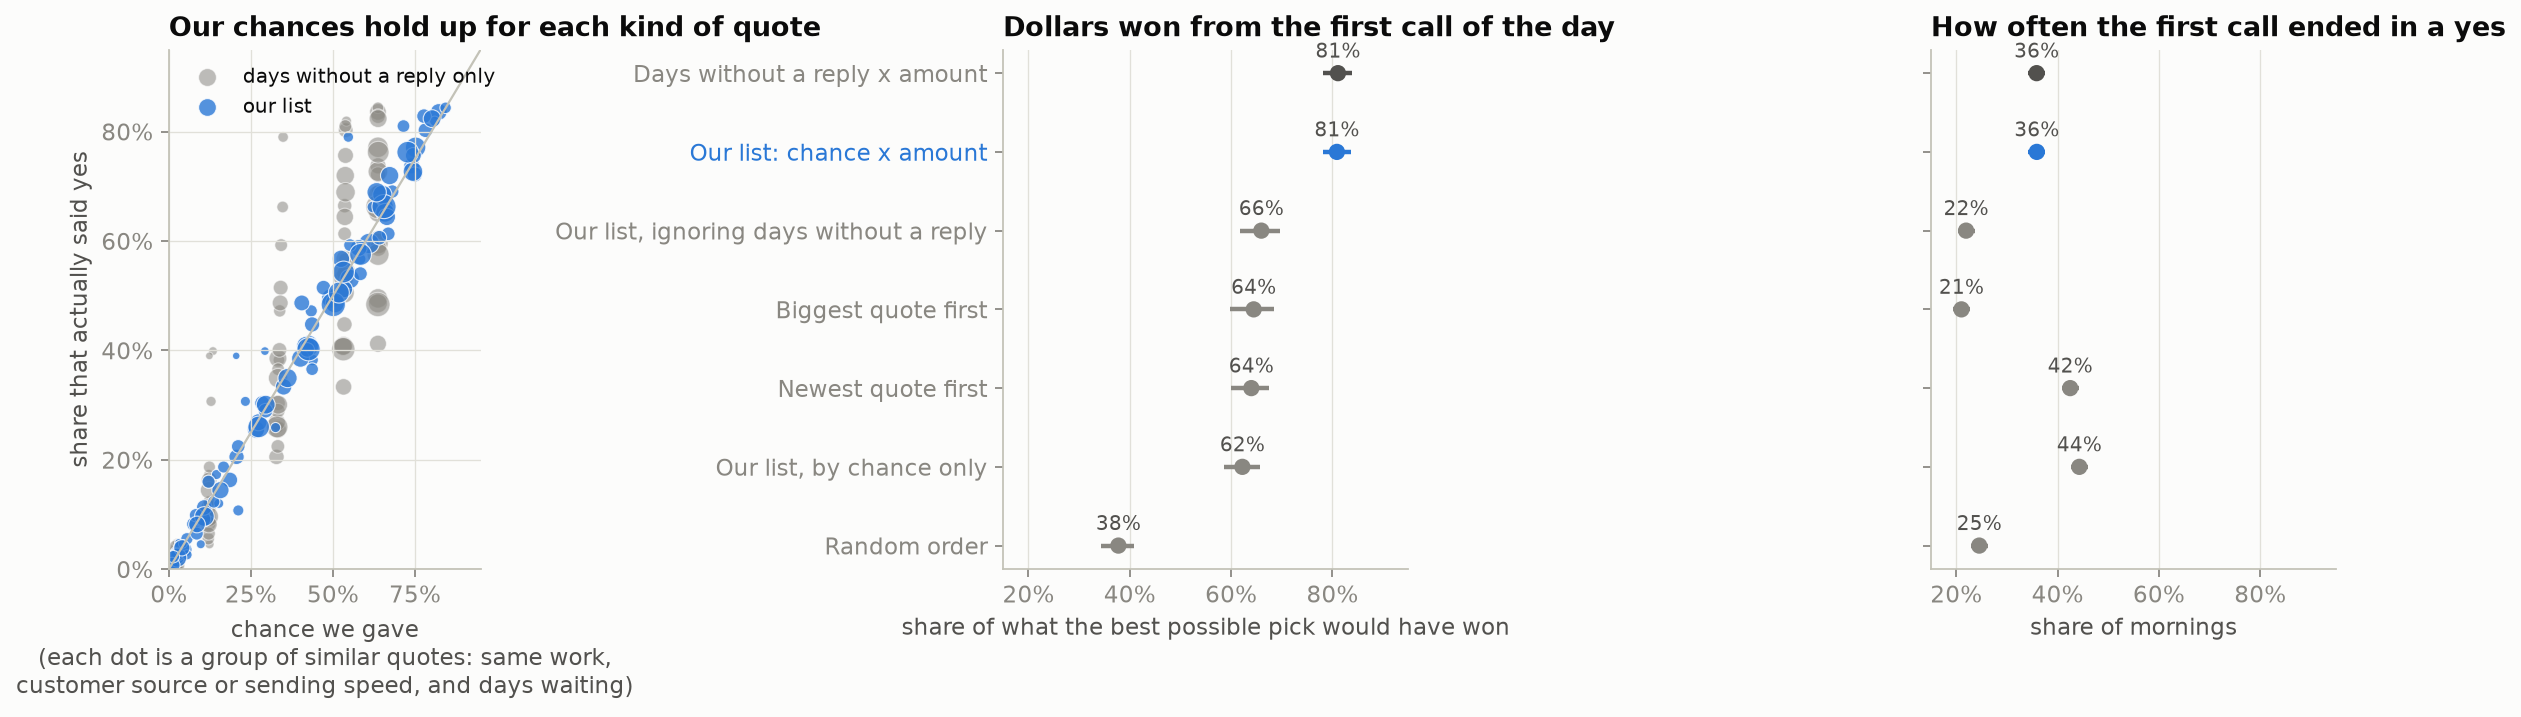

In [9]:
age_cells = backtest.subgroup_calibration(predictions.assign(p_now=predictions["p_age_only"]))
figures.ASSETS.mkdir(exist_ok=True)
figures.evidence(summary, cells, age_cells)
display(Image(figures.ASSETS / "evidence.png"))

## Does it hold month to month?

In [10]:
monthly = backtest.by_month(result.lists).query(
    "k == 1 and scorer in [@OUR_LIST, @DAYS_QUIET_X_AMOUNT, @NEWEST_FIRST, @BIGGEST_FIRST]")
display(monthly.pivot(index="month", columns="scorer", values="dollar_capture").round(3)
        .rename_axis(columns="dollars won, first call"))

"dollars won, first call",Biggest quote first,Days without a reply x amount,Newest quote first,Our list: chance x amount
month,,,,
2024-09,0.689,0.858,0.654,0.831
2024-10,0.675,0.844,0.691,0.847
2024-11,0.575,0.800,0.646,0.802
2024-12,0.658,0.748,0.568,0.758


Yes, our list is ahead of both rules of thumb every month.

## Would a different judgement call change the answer?

Each row changes one decision and reruns the whole replay (300 re-draws each, to keep it quick).

In [11]:
display(sensitivity.run(quotes, settings).round(3))

,what changed,our list,days waiting x amount,best rule of thumb,its dollars won,our lead over it,lead low,lead high,lead over days waiting x amount,average chance gap,groups missed beyond luck
0,nothing (as built),0.809,0.811,Biggest quote first,0.645,0.164,0.123,0.203,-0.002,0.007,3
1,stale open quotes counted as lost,0.803,0.802,Newest quote first,0.642,0.161,0.128,0.193,0.001,0.005,2
2,"wait 60 days, not 45, before learning from a quote",0.807,0.811,Biggest quote first,0.645,0.163,0.123,0.202,-0.004,0.007,3
3,"reply speeds may use groups of 50 quotes, not 200",0.809,0.811,Biggest quote first,0.645,0.164,0.123,0.203,-0.002,0.007,3
4,reply speeds also learned by customer source,0.811,0.811,Biggest quote first,0.645,0.166,0.128,0.205,0.000,0.007,5


Counting the stale "open" quotes as lost, waiting 60 days instead of 45 before learning from a
quote, letting reply speeds use smaller groups, or learning them by customer source: none of it
changes the picture. Our list stays about 16 points ahead of the best rule of thumb, level with
the simple rival, and its chances stay within a point of reality on average.